In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph

from stem_agent.config import auto_focus_settings, check_fov, sam_settings
from stem_agent.nodes.auto_focus_node import auto_focus_node
from stem_agent.nodes.eds_node import eds_node, eds_settings
from stem_agent.nodes.overview_node import overview_node
from stem_agent.nodes.preflight_node import preflight_node
from stem_agent.nodes.sam_segment_node import sam_segment_node
from stem_agent.nodes.save_node import save_node
from stem_agent.nodes.set_fov_node import set_fov_node
from stem_agent.nodes.status_node import status_node
from stem_agent.states.experiment_state import ParticleRunState
from stem_agent.utils.plots import plot_graph

In [2]:
SETTINGS = {
    "instrument": "real",            # "twin" or "real"
    "run_tag": "autofocus_sam_eds",
    "auto_focus": {},                
    "sam": {"min_visible": 0.5, "min_diameter_nm": 2.0, "max_diameter_nm": 30.0},     
    "max_particles": 10,              # EDS on the 5 largest particles
}


def check(settings: dict) -> None:
    """Every node's settings, before anything moves. ValueError on a typo or a bad value."""
    if "auto_focus" not in settings:   # without it auto_focus_node quietly skips
        raise ValueError('settings needs "auto_focus" ({} = defaults), otherwise the node is skipped')
    if settings["auto_focus"].get("fov_m") is not None:
        raise ValueError("this notebook keeps the microscope's FOV: leave auto_focus fov_m out")
    auto_focus_settings(settings)
    sam_settings(settings)
    eds_settings(settings)


check(SETTINGS)                        # fails here on a typo, before connecting to anything

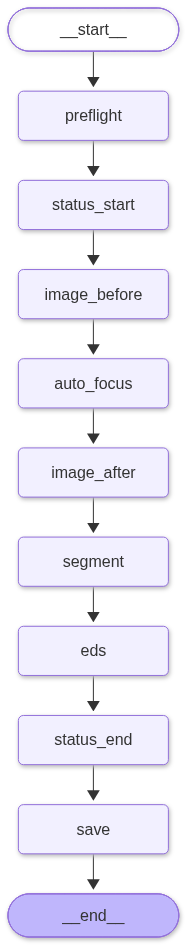

In [6]:
STOP = ("failed", "no_particles")    # no particles: skip EDS, still save


def go(next_node):
    """Router: the next node, or status_end when the run failed / found no particles."""
    return lambda state: "status_end" if state.get("run_status") in STOP else next_node


builder = StateGraph(ParticleRunState)
builder.add_node("preflight", preflight_node)        # MCP + Tiled + run folder
builder.add_node("status_start", status_node)        # snapshot; stops the run if not ready
builder.add_node("image_before", overview_node)      # 1) image before  -> images[0]
builder.add_node("auto_focus", auto_focus_node)      # 2) OptiSTEM C1/A1
builder.add_node("image_after", overview_node)       # 3) image after   -> images[1] = overview
builder.add_node("segment", sam_segment_node)        # 4) SAM2 particles on the after image
builder.add_node("eds", eds_node)                    # 5) EDS on the particles
builder.add_node("status_end", status_node)          # final snapshot
builder.add_node("save", save_node)                  # summary.json + summary.png, always

steps = ["preflight", "status_start", "image_before", "auto_focus", "image_after", "segment", "eds"]
builder.add_edge(START, steps[0])
for name, next_name in zip(steps, steps[1:]):        # each step: the next one, or jump to status_end
    builder.add_edge(name, next_name)
builder.add_edge("eds", "status_end")
builder.add_edge("status_end", "save")
builder.add_edge("save", END)

graph = builder.compile()
graph

In [ ]:
check(SETTINGS)                                      # stops here on a typo, before anything moves
state = await graph.ainvoke({"settings": SETTINGS})
print(state["run_status"], state.get("errors", []))